# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Delos Santos, Mico
- _Student No._: 2024-35117
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

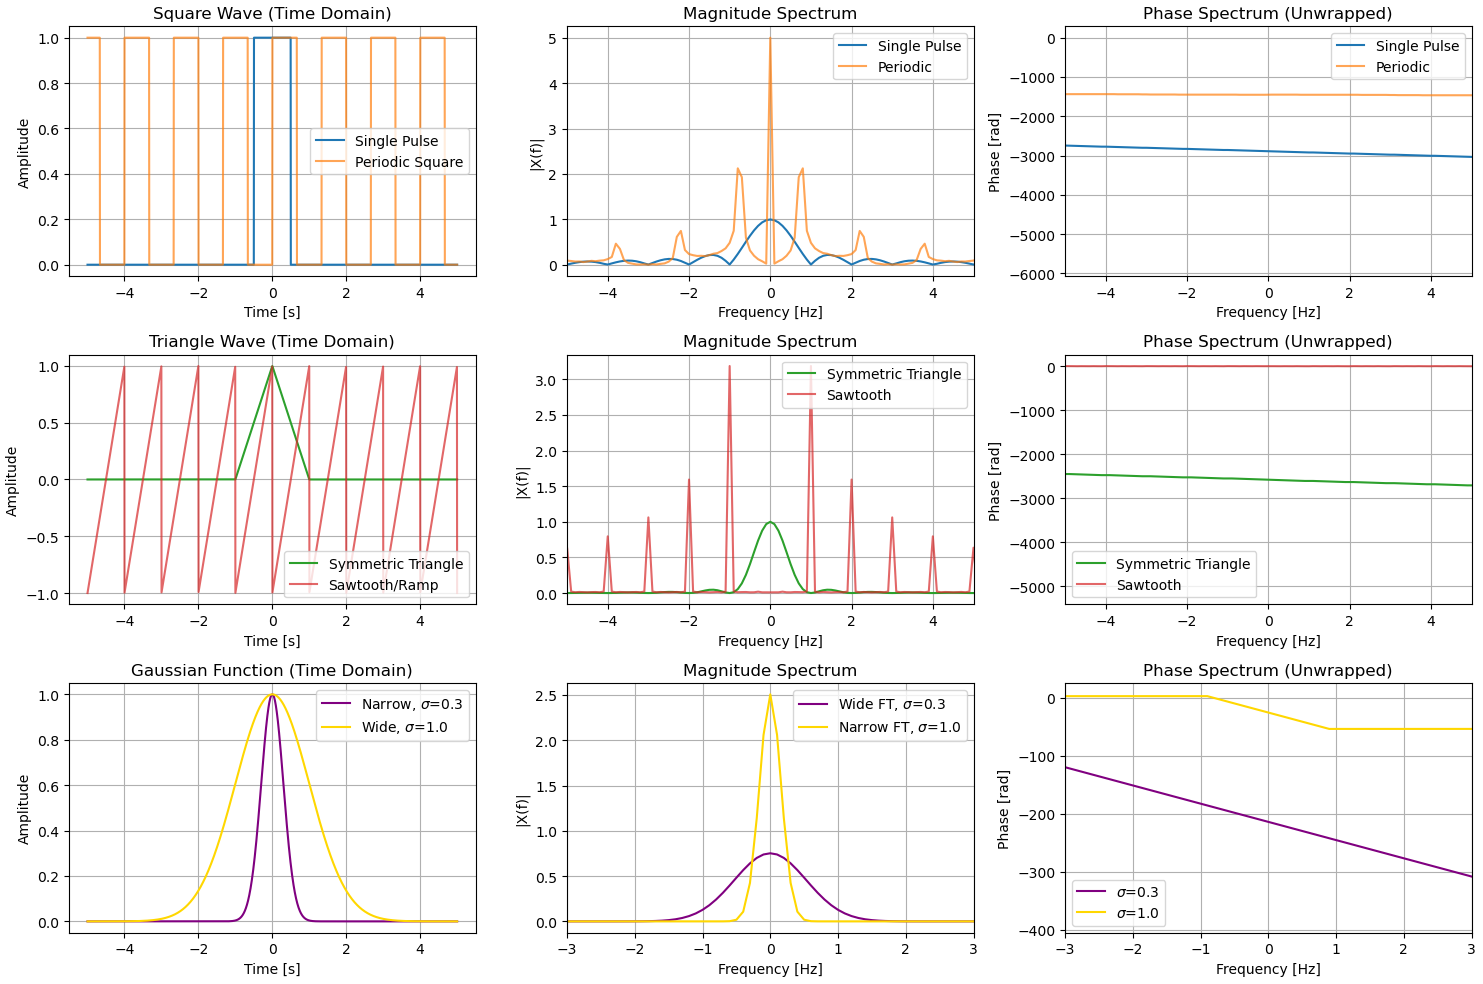

Fig. 1. Fourier Transform of square wave, triangular wave, and Gaussian function

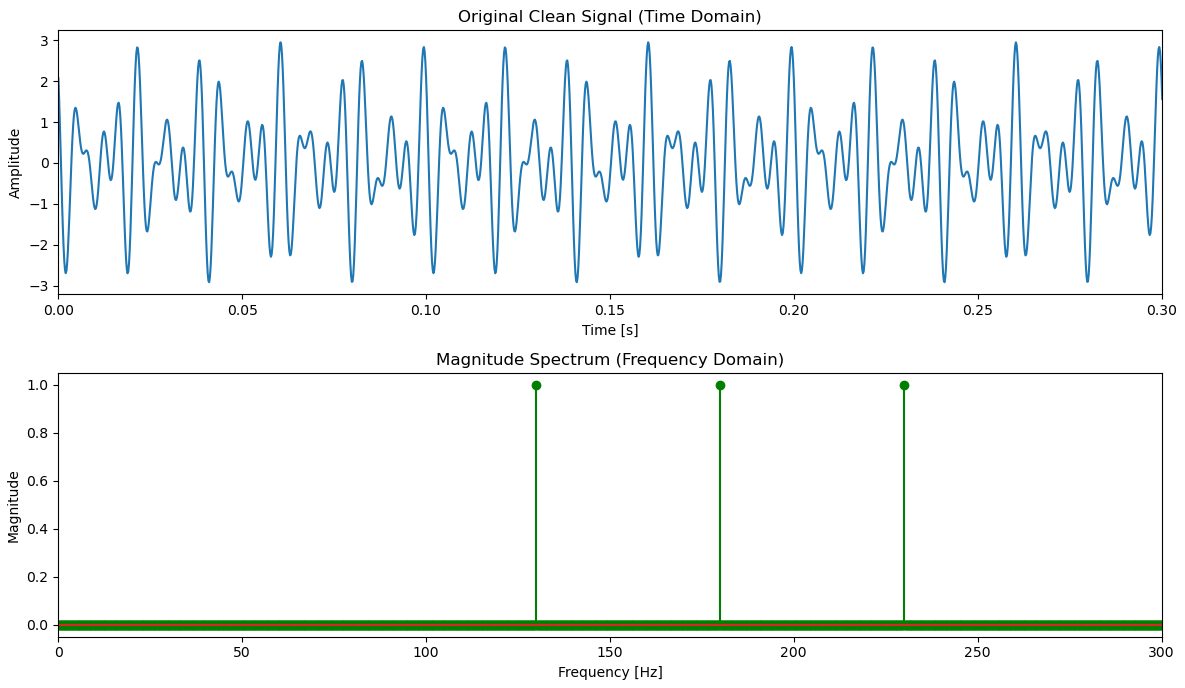

Fig. 2a. Fourier Transform - Signal Processing in 1D

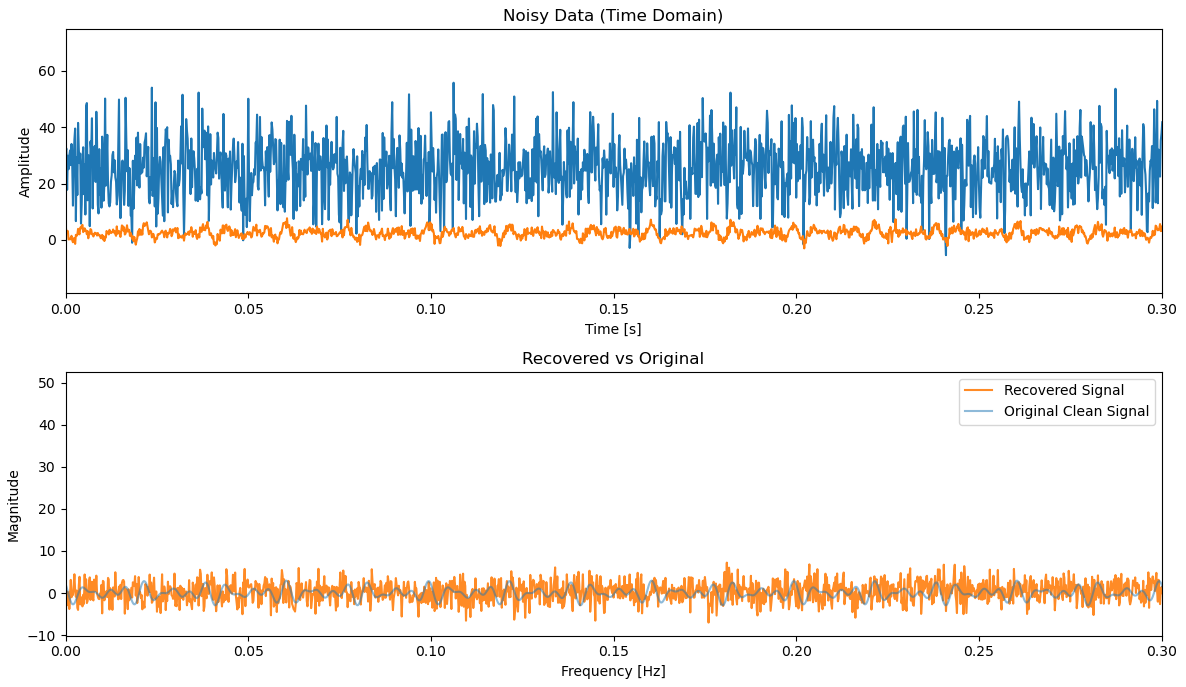

Fig. 2b. Noisy and the Recovered vs Original Signal

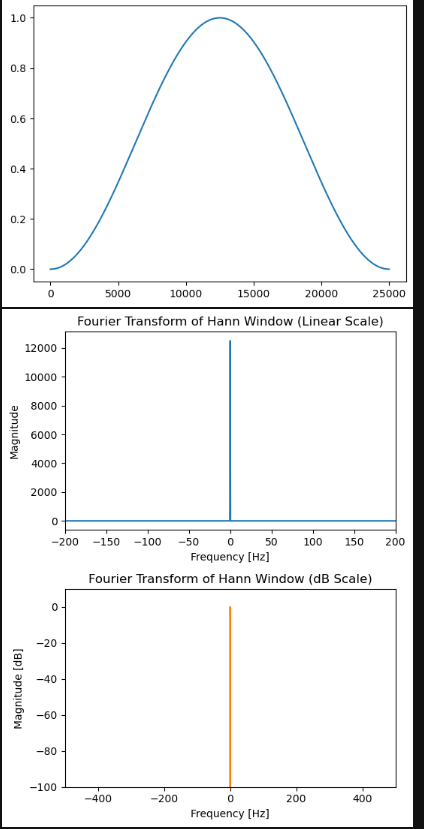

Fig. 2c. Fourier Transform of Hann Window

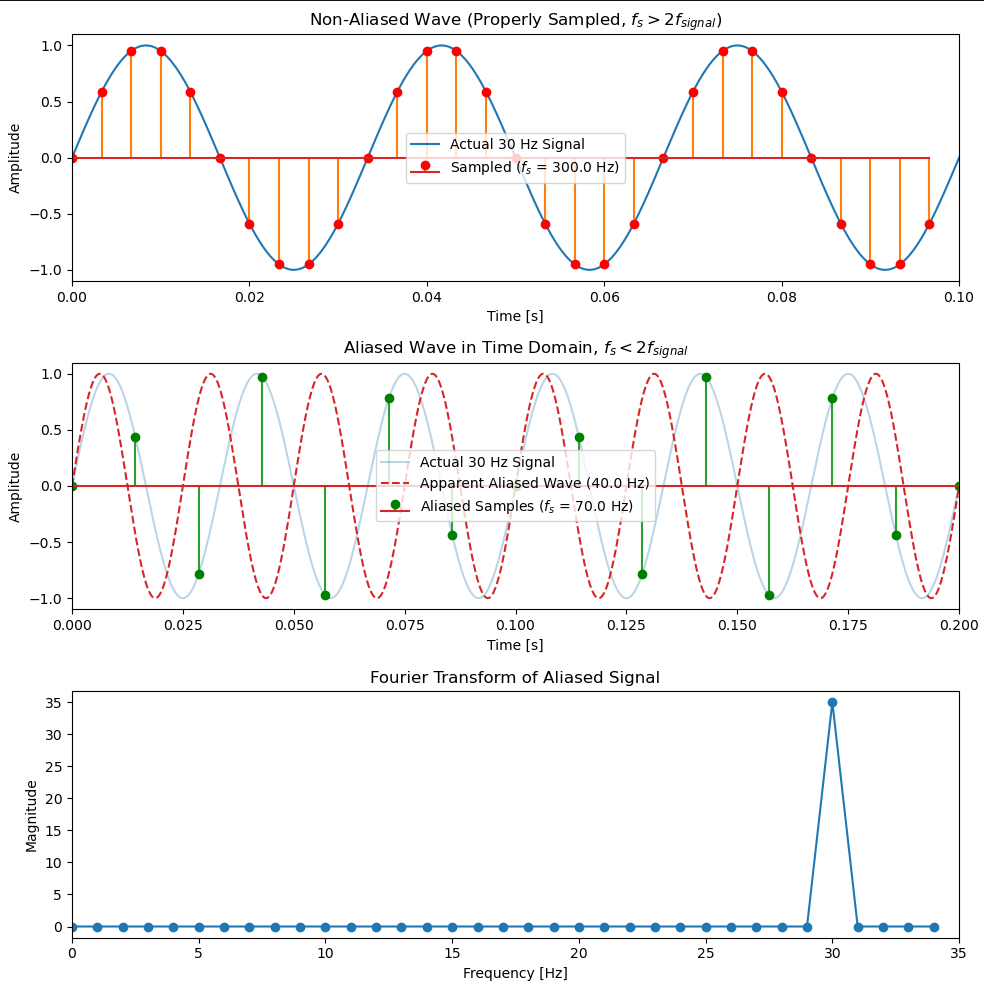

Fig. 3. Aliasing using sampling frequency of Nyquist frequency

### Report discussion

Problem 1:

Square Wave: A single square pulse produces a continuous $\text{sinc}$-shaped magnitude spectrum, whereas a periodic square wave discretizes the spectrum into harmonic line components. Repeating the pulse in time effectively samples the continuous frequency spectrum.  

Triangle Wave: The symmetric triangle pulse yields a $\text{sinc}^2$ envelope that decays faster than a square wave, $1/f^2$, due to its smoother slopes. In contrast, the sawtooth ramp has a sharp reset discontinuity, resulting in higher high-frequency harmonic energy and an asymmetric phase response.   

Gaussian Function: Shows the time-frequency uncertainty principle, narrowing the Gaussian in time ($\sigma = 0.3$) broadens its Fourier magnitude spectrum in frequency. Conversely, widening the time-domain Gaussian compresses its frequency spectrum into a narrower peak centered at $0\text{ Hz}$.   

Problem 2:

With $N<25000$, if we lower $N$, we will get a reduced observation window length, degrading the frequency resolution, that is $\Delta f=\frac{f_s}{N}$, also widening the peaks. With that, it would be difficult to recover the noisy signal since the widened peaks blurring the noise. Also, there is a limit for $N$, because we can't use too few data points to separate the real signal from the background noise.

Problem 3:

After getting their Fourier transforms, we see that they are $\textbf{not}$ the same. As seen. the non-aliased signal w/ $f_s = 300Hz$ correctly peaks at $30Hz$, as I set $f_{signal} = 30 Hz$ as the true signal frequency. Meanwhile, the aliased singla w/ $f_2 = 70Hz$ undersamples the wave, causing a $40Hz$ frequency difference to fold across the $35Hz$ Nyquist limit, $\frac{f_2}{2}$, generating a wrong peak at $30Hz$.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitudenitudenitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

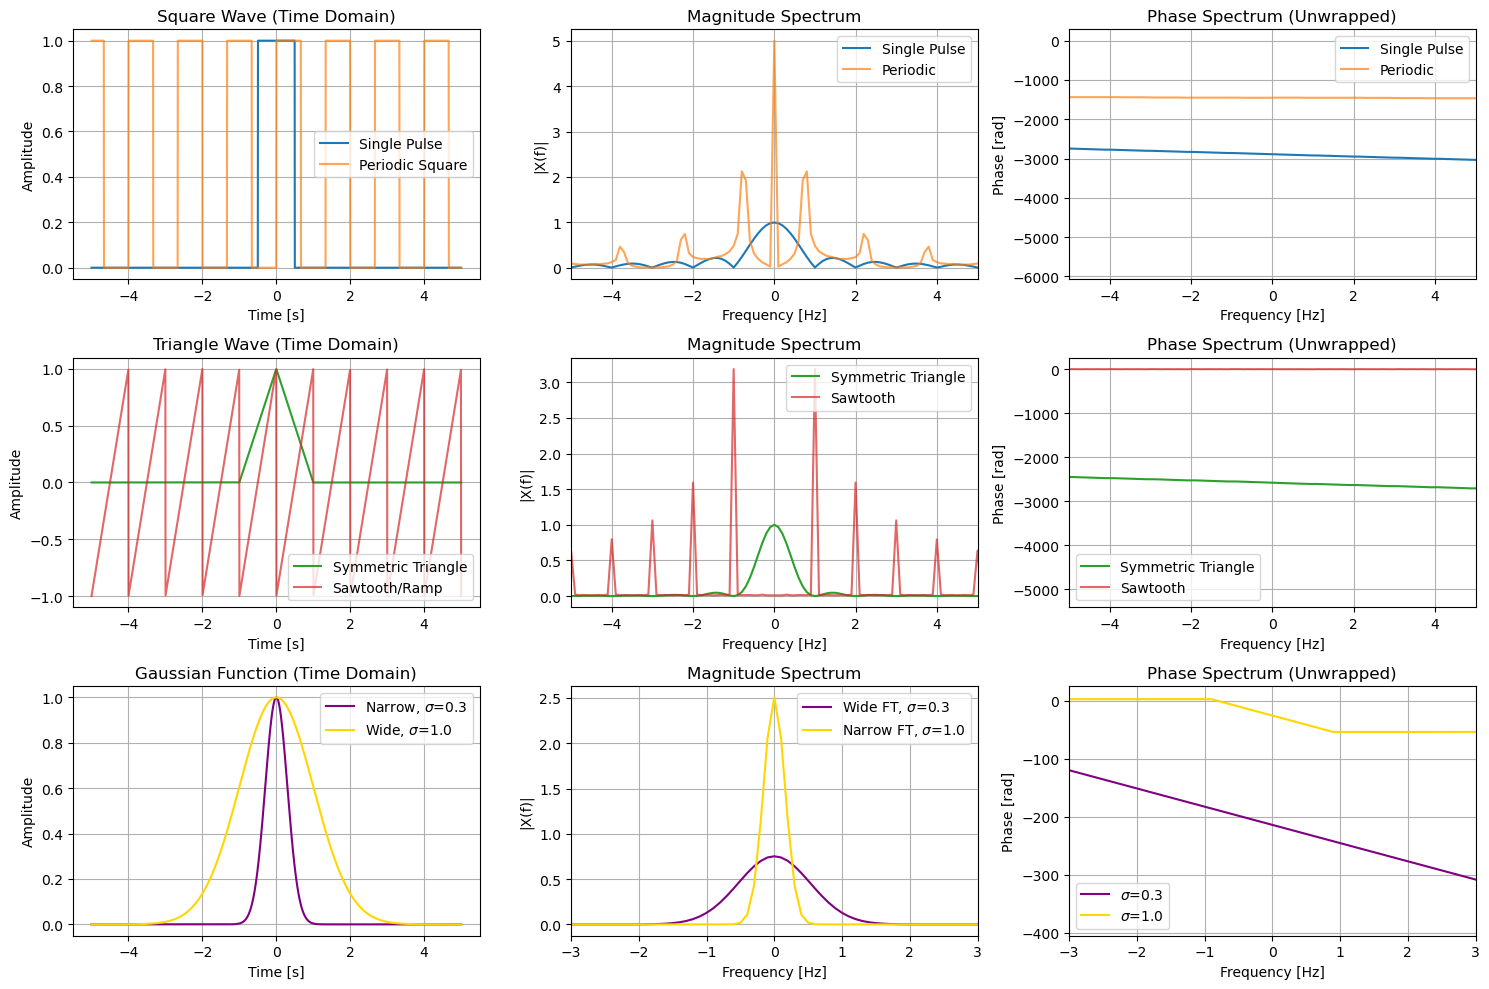

In [3]:
N = 2048
t = np.linspace(-5,5,N)
dt = t[1] - t[0]
fs = 1/dt                  #sampling frequency
frequency = np.fft.fftshift(np.fft.fftfreq(N,d=dt))

fig, axs = plt.subplots(3,3, figsize=(15,10))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

square_1 = np.where(np.abs(t) <= 0.5, 1.0, 0.0)
square_wave = 0.5*(np.sign(np.sin(2*np.pi*0.75*t)) + 1)

#fft computations
#square wave
fft_square_1 = np.fft.fftshift(np.fft.fft(square_1))*dt
magnitude_square_1 = np.abs(fft_square_1)
phase_square_1 = np.unwrap(np.angle(fft_square_1))

fft_square_wave = np.fft.fftshift(np.fft.fft(square_wave))*dt
magnitude_square_wave = np.abs(fft_square_wave)
phase_square_wave = np.unwrap(np.angle(fft_square_wave))

axs[0, 0].plot(t, square_1, label='Single Pulse', color='tab:blue')
axs[0, 0].plot(t, square_wave, label='Periodic Square', color='tab:orange', alpha=0.7)
axs[0, 0].set_title("Square Wave (Time Domain)")
axs[0, 0].set_xlabel("Time [s]")
axs[0, 0].set_ylabel("Amplitude")
axs[0, 0].legend()
axs[0, 0].grid(True)

axs[0, 1].plot(frequency, magnitude_square_1, label='Single Pulse', color='tab:blue')
axs[0, 1].plot(frequency, magnitude_square_wave, label='Periodic', color='tab:orange', alpha=0.7)
axs[0, 1].set_title("Magnitude Spectrum")
axs[0, 1].set_xlabel("Frequency [Hz]")
axs[0, 1].set_ylabel("|X(f)|")
axs[0, 1].set_xlim(-5, 5)
axs[0, 1].legend()
axs[0, 1].grid(True)

axs[0, 2].plot(frequency, phase_square_1, label='Single Pulse', color='tab:blue')
axs[0, 2].plot(frequency, phase_square_wave, label='Periodic', color='tab:orange', alpha=0.7)
axs[0, 2].set_title("Phase Spectrum (Unwrapped)")
axs[0, 2].set_xlabel("Frequency [Hz]")
axs[0, 2].set_ylabel("Phase [rad]")
axs[0, 2].set_xlim(-5, 5)
axs[0, 2].legend()
axs[0, 2].grid(True)

#triangular wave
tri_sym = np.maximum(0, 1 - np.abs(t))
sawtooth = 2.0 * ((t * 1.0) % 1.0) - 1.0

fft_tri_sym = np.fft.fftshift(np.fft.fft(tri_sym)) * dt
magnitude_tri_sym = np.abs(fft_tri_sym)
phase_tri_sym = np.unwrap(np.angle(fft_tri_sym))

fft_saw = np.fft.fftshift(np.fft.fft(sawtooth)) * dt
magnitude_saw = np.abs(fft_saw)
phase_saw = np.unwrap(np.angle(fft_saw))

axs[1, 0].plot(t, tri_sym, label='Symmetric Triangle', color='tab:green')
axs[1, 0].plot(t, sawtooth, label='Sawtooth/Ramp', color='tab:red', alpha=0.7)
axs[1, 0].set_title("Triangle Wave (Time Domain)")
axs[1, 0].set_xlabel("Time [s]")
axs[1, 0].set_ylabel("Amplitude")
axs[1, 0].legend()
axs[1, 0].grid(True)

axs[1, 1].plot(frequency, magnitude_tri_sym, label='Symmetric Triangle', color='tab:green')
axs[1, 1].plot(frequency, magnitude_saw, label='Sawtooth', color='tab:red', alpha=0.7)
axs[1, 1].set_title("Magnitude Spectrum")
axs[1, 1].set_xlabel("Frequency [Hz]")
axs[1, 1].set_ylabel("|X(f)|")
axs[1, 1].set_xlim(-5, 5)
axs[1, 1].legend()
axs[1, 1].grid(True)

axs[1, 2].plot(frequency, phase_tri_sym, label='Symmetric Triangle', color='tab:green')
axs[1, 2].plot(frequency, phase_saw, label='Sawtooth', color='tab:red', alpha=0.7)
axs[1, 2].set_title("Phase Spectrum (Unwrapped)")
axs[1, 2].set_xlabel("Frequency [Hz]")
axs[1, 2].set_ylabel("Phase [rad]")
axs[1, 2].set_xlim(-5, 5)
axs[1, 2].legend()
axs[1, 2].grid(True)

#gaussian function
sigma1 = 0.3
sigma2 = 1.0

Gauss1 = np.exp(-t**2 / (2 * sigma1**2))
Gauss2 = np.exp(-t**2 / (2 * sigma2**2))

fft_Gauss1 = np.fft.fftshift(np.fft.fft(Gauss1)) * dt
magnitude_Gauss1 = np.abs(fft_Gauss1)
phase_Gauss1 = np.unwrap(np.angle(fft_Gauss1))

fft_Gauss2 = np.fft.fftshift(np.fft.fft(Gauss2)) * dt
magnitude_Gauss2 = np.abs(fft_Gauss2)
phase_Gauss2 = np.unwrap(np.angle(fft_Gauss2))

axs[2, 0].plot(t, Gauss1, label=f'Narrow, $\sigma$={sigma1}', color='purple')
axs[2, 0].plot(t, Gauss2, label=f'Wide, $\sigma$={sigma2}', color='gold')
axs[2, 0].set_title("Gaussian Function (Time Domain)")
axs[2, 0].set_xlabel("Time [s]")
axs[2, 0].set_ylabel("Amplitude")
axs[2, 0].legend()
axs[2, 0].grid(True)

axs[2, 1].plot(frequency, magnitude_Gauss1, label=f'Wide FT, $\sigma$={sigma1}', color='purple')
axs[2, 1].plot(frequency, magnitude_Gauss2, label=f'Narrow FT, $\sigma$={sigma2}', color='gold')
axs[2, 1].set_title("Magnitude Spectrum")
axs[2, 1].set_xlabel("Frequency [Hz]")
axs[2, 1].set_ylabel("|X(f)|")
axs[2, 1].set_xlim(-3, 3)
axs[2, 1].legend()
axs[2, 1].grid(True)

axs[2, 2].plot(frequency, phase_Gauss1, label=f'$\sigma$={sigma1}', color='purple')
axs[2, 2].plot(frequency, phase_Gauss2, label=f'$\sigma$={sigma2}', color='gold')
axs[2, 2].set_title("Phase Spectrum (Unwrapped)")
axs[2, 2].set_xlabel("Frequency [Hz]")
axs[2, 2].set_ylabel("Phase [rad]")
axs[2, 2].set_xlim(-3, 3)
axs[2, 2].legend()
axs[2, 2].grid(True)

plt.tight_layout()
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [164]:
#f3 = 500
#t3 = np.linspace(0,1, f3, endpoint=False)
#signal = 2*np.sin(2*np.pi*50*t3) + 0.5*np.sin(2*np.pi*120*t3)
#fft_vals = np.fft.fft(signal)
#freq3 = np.fft.fftfreq(len(signal), 1/f3)
#magnitudenitude3 = np.abs(fft_vals[:len(freq)//2])*2/len(signal)

#fig, axs = plt.subplots(1,3, figsize=(14,5))

#axs[2].plot(freq[:len(freq)//2],magnitudenitude)
#axs[2].set_title("Square-wave")
#axs[2].set_xlabel("Frequency (Hz)")
#axs[2].set_ylabel("Amplitude")
#axs[2].grid(True)

#plt.show()


In [8]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #spacing = 0.0002 => frequency = 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

#fft computations, clean signal
fft_signal = np.fft.fft(signal_original)
freq_signal = np.fft.fftfreq(len(signal_original), dt)
magnitude_signal = np.abs(fft_signal[:len(freq_signal)//2] * 2/len(signal_original))

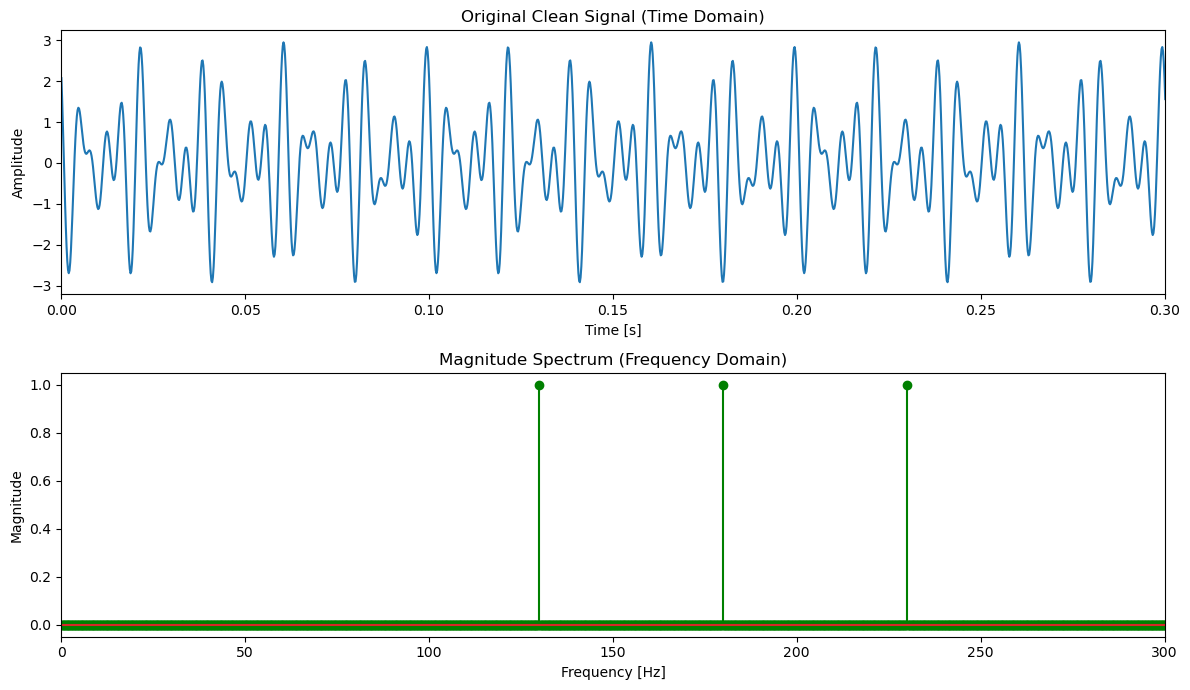

In [26]:
fig, ax = plt.subplots(2,1, figsize= (12,7))
ax[0].plot(t_, signal_original)
ax[0].set_xlim(0,0.3)
ax[0].set_title("Original Clean Signal (Time Domain)")
ax[0].set_xlabel("Time [s]")
ax[0].set_ylabel("Amplitude")

ax[1].stem(freq_signal[:len(freq_signal)//2], magnitude_signal, 'g')
ax[1].set_xlim(0,300)
ax[1].set_title("Magnitude Spectrum (Frequency Domain)")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Magnitude")

plt.tight_layout()
plt.show()

In [4]:
#FILL: Plot the fourier transform of the clean, original signal

In [102]:
signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(frequency, phase)], axis=0)

In [12]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise
mean = 5
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

#Hann window, fft of noisy
H_window = np.hanning(len(noisy_data))
noisy_Fourier = np.fft.fft(noisy_data * H_window)
mag_noisy_windowed = np.abs(noisy_Fourier)

threshold = 1000  #filter out noise floor retaining signal peaks
noisy_fft_filtered = np.where(mag_noisy_windowed > threshold, noisy_Fourier, 0)

#inverse fft, recover signal
recovered_signal = np.real(np.fft.ifft(noisy_fft_filtered))

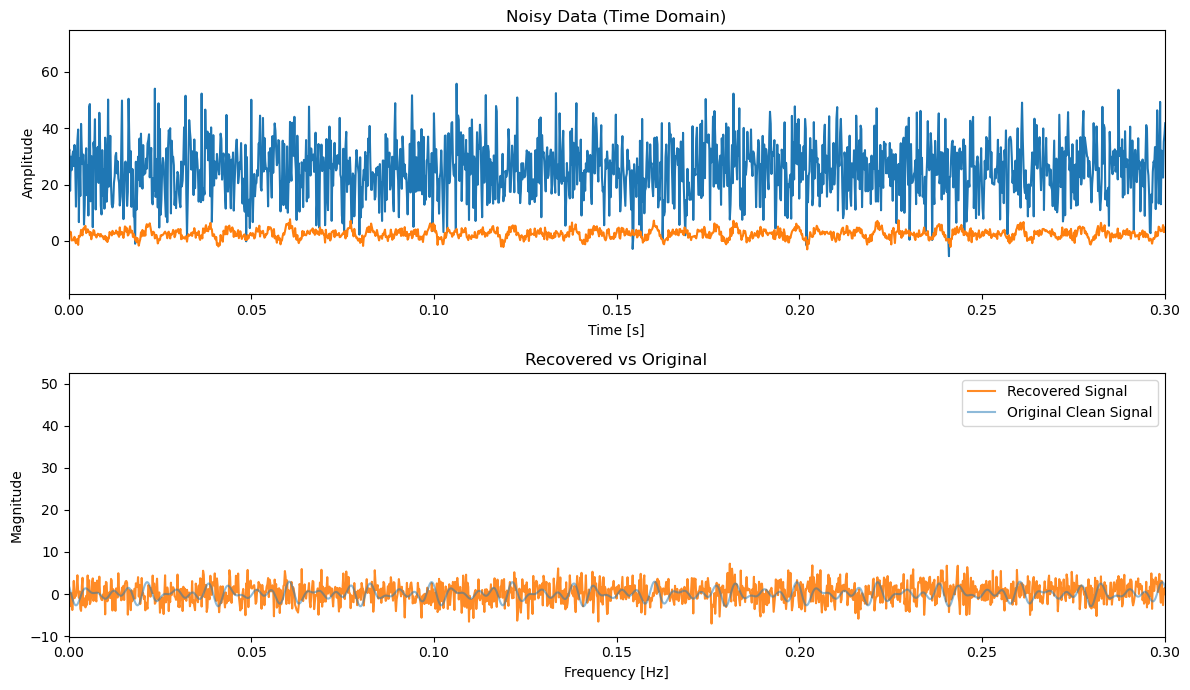

In [25]:
fig, axs = plt.subplots(2,1, figsize= (12,7))

axs[0].plot(t_, noisy_data)
axs[0].set_xlim(0,0.3)
axs[0].set_title("Noisy Data (Time Domain)")
axs[0].set_xlabel("Time [s]")
axs[0].set_ylabel("Amplitude")
axs[0].plot(t_,noisy5)

axs[1].plot(t_, recovered_signal, color='tab:orange', label='Recovered Signal', alpha=0.9)
axs[1].plot(t_, signal_original, color='tab:blue', linestyle='-', label='Original Clean Signal', alpha=0.5)
axs[1].set_xlim(0,0.3)
axs[1].set_title("Recovered vs Original")
axs[1].set_xlabel("Frequency [Hz]")
axs[1].set_ylabel("Magnitude")
axs[1].legend()

plt.tight_layout()
plt.show()

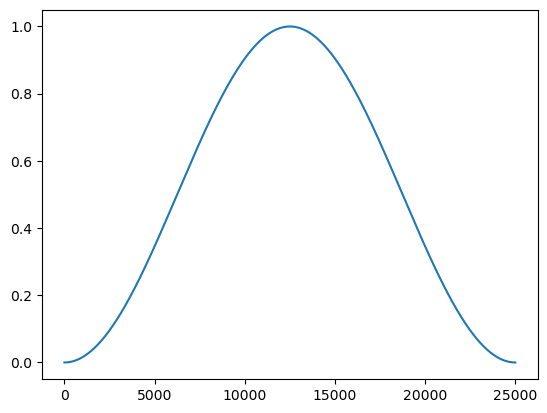

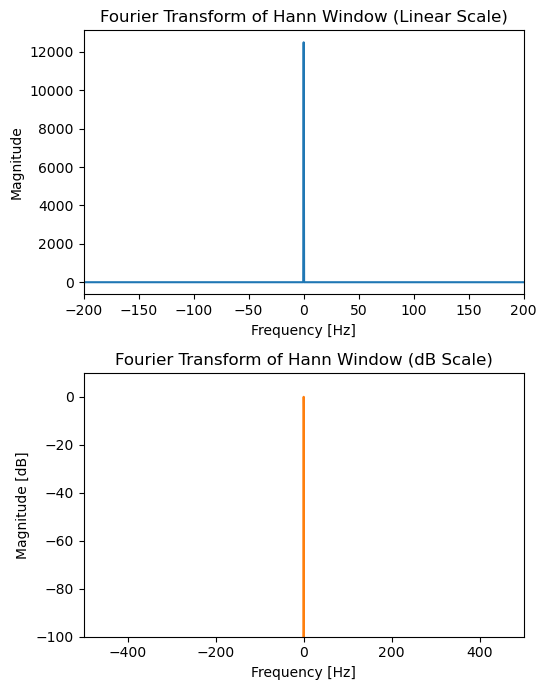

In [43]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

#fft of Hann window and shift zero-frequency to the center
window_fft = np.fft.fft(window)
window_freqs = np.fft.fftfreq(len(window), dt)

window_fft_shifted = np.fft.fftshift(window_fft)
window_freqs_shifted = np.fft.fftshift(window_freqs)

fig, ax = plt.subplots(2, 1, figsize=(5.57, 7))

# Linear scale, near the center
ax[0].plot(window_freqs_shifted, np.abs(window_fft_shifted), color='tab:blue')
ax[0].set_title("Fourier Transform of Hann Window (Linear Scale)")
ax[0].set_xlabel("Frequency [Hz]")
ax[0].set_ylabel("Magnitude")
ax[0].set_xlim(-200, 200) #main lobe zoom

# Log / dB scale, lobes dropping off
magnitude_normalized = np.abs(window_fft_shifted) / np.max(np.abs(window_fft_shifted))
with np.errstate(divide='ignore', invalid='ignore'):
    window_dB = 20 * np.log10(magnitude_normalized)

ax[1].plot(window_freqs_shifted, window_dB, color='tab:orange')
ax[1].set_title("Fourier Transform of Hann Window (dB Scale)")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Magnitude [dB]")
ax[1].set_xlim(-500, 500)
ax[1].set_ylim(-100, 10)

plt.tight_layout()
plt.show()

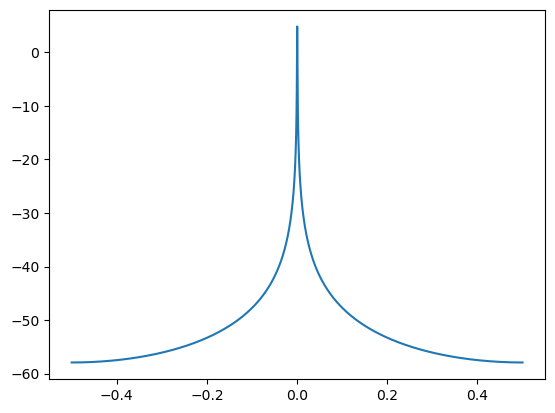

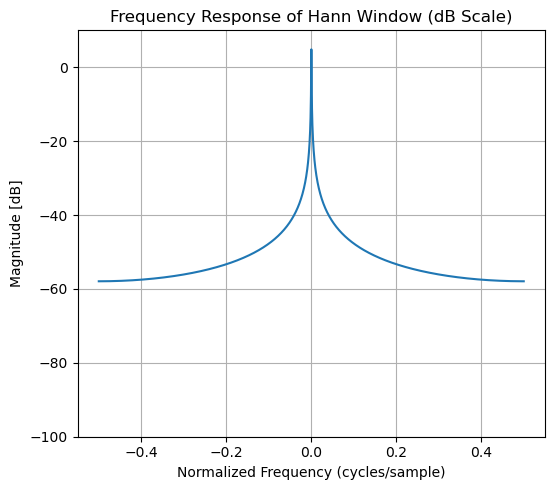

In [51]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

#fft of Hann window
N_fft = 2048
A = np.fft.fft(window, 2048) / 25.5
magnitudenitudenitude = np.abs(np.fft.fftshift(A))
frequency = np.linspace(-0.5, 0.5, len(A))
with np.errstate(divide='ignore', invalid='ignore'):
    response = 20*np.log10(magnitudenitudenitude)
plt.plot(frequency, response)

fig, ax = plt.subplots(figsize=(5.65, 5))
ax.plot(frequency, response, color='tab:blue')
ax.set_title("Frequency Response of Hann Window (dB Scale)")
ax.set_xlabel("Normalized Frequency (cycles/sample)")
ax.set_ylabel("Magnitude [dB]")
ax.set_ylim(-100, 10)
ax.grid(True)
plt.tight_layout()
plt.show()

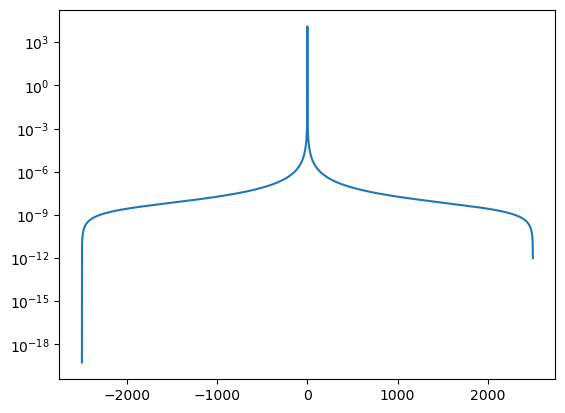

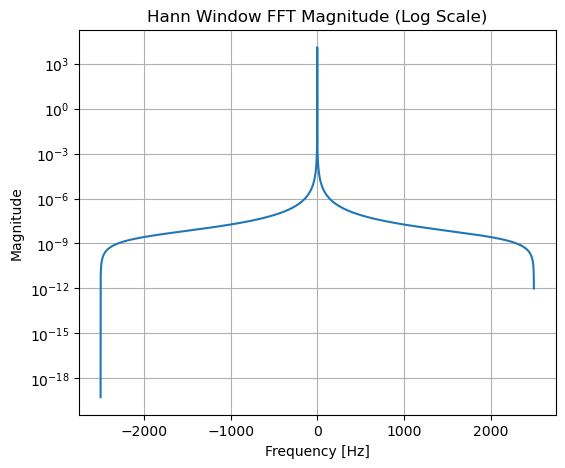

In [63]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

#shifted fft magnitude and frequency bins
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

plt.figure(figsize=(6.15, 5))
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')
plt.title("Hann Window FFT Magnitude (Log Scale)")
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()

In [10]:
noisyFourier = np.fft.fft(noisy_data*window)

# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


In [11]:
# Fill: Plot the magnitudenitudenitude of fourier transform of the noisy data multiplied by the hanning window

In [12]:
# Fill: Find a suitable threshold value to filter the noise in fourier space

In [13]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

In [14]:
# Plot the recovered signal
# fig, ax = plt.subplots(figsize= (12,5))
# ax.plot(t_, recoveredSignal)
# ax.set_xlim(0,0.3)

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

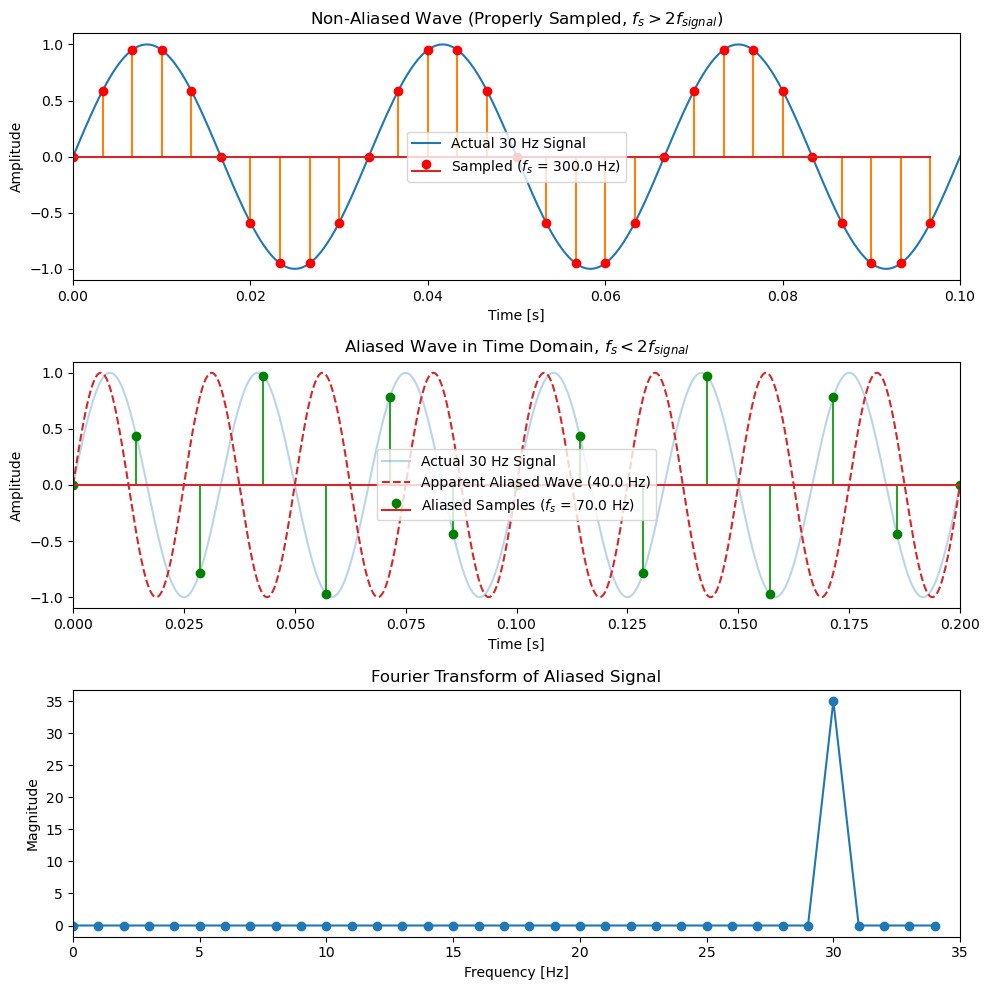

In [81]:
# Define parameters
f_signal = 30       #true signal frequency [Hz]
T_duration = 1.0      #duration [s]

#sampling frequencies
fs_good = 300.0       #above Nyquist (300 > 100 Hz)
fs_bad = 70.0         #below Nyquist (70 < 100 Hz)

#time vectors
t_good = np.arange(0, T_duration, 1/fs_good)
t_bad = np.arange(0, T_duration, 1/fs_bad)
t_dense = np.linspace(0, T_duration, 10000) # High-res for continuous look

#generate signals
signal_continuous = np.sin(2 * np.pi * f_signal * t_dense)
signal_good = np.sin(2 * np.pi * f_signal * t_good)
signal_bad = np.sin(2 * np.pi * f_signal * t_bad)

#fft
fft_good = np.fft.fft(signal_good)
freqs_good = np.fft.fftfreq(len(signal_good), 1/fs_good)

fft_bad = np.fft.fft(signal_bad)
freqs_bad = np.fft.fftfreq(len(signal_bad), 1/fs_bad)

#plots
fig, axs = plt.subplots(3, 1, figsize=(10, 10))

#properly sampled, Non-Aliased time domain
axs[0].plot(t_dense, signal_continuous, label='Actual 30 Hz Signal')
axs[0].stem(t_good[:30], signal_good[:30], linefmt='tab:orange', markerfmt='ro', label=f'Sampled ($f_s$ = {fs_good} Hz)')
axs[0].set_title("Non-Aliased Wave (Properly Sampled, $f_s > 2f_{signal}$)")
axs[0].set_xlabel("Time [s]")
axs[0].set_ylabel("Amplitude")
axs[0].set_xlim(0, 0.1)
axs[0].legend()

#aliased time domain
f_alias = abs(f_signal - fs_bad) # Apparent frequency = 20 Hz
axs[1].plot(t_dense, signal_continuous, label='Actual 30 Hz Signal', color='tab:blue', alpha=0.3)
axs[1].stem(t_bad[:30], signal_bad[:30], linefmt='tab:green', markerfmt='go', label=f'Aliased Samples ($f_s$ = {fs_bad} Hz)')
axs[1].plot(t_dense, np.sin(2 * np.pi * f_alias * t_dense), color='tab:red', linestyle='--', label=f'Apparent Aliased Wave ({f_alias} Hz)')
axs[1].set_title("Aliased Wave in Time Domain, $f_s < 2f_{signal}$")
axs[1].set_xlabel("Time [s]")
axs[1].set_ylabel("Amplitude")
axs[1].set_xlim(0, 0.2)
axs[1].legend()

#ft of aliased signal
pos_mask = freqs_bad >= 0
axs[2].plot(freqs_bad[pos_mask], np.abs(fft_bad[pos_mask]), marker='o')
axs[2].set_title("Fourier Transform of Aliased Signal")
axs[2].set_xlabel("Frequency [Hz]")
axs[2].set_ylabel("Magnitude")
axs[2].set_xlim(0, fs_bad/2)

plt.tight_layout()
plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imagnitudenitudeinary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

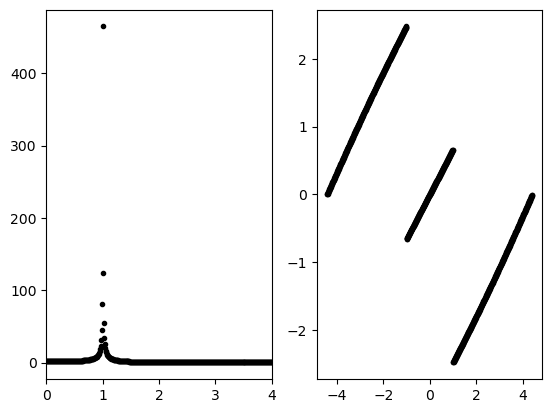

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

frequency = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_magnitudenitude = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(frequency, Yk_magnitudenitude, "k.")
ax[1].plot(frequency, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

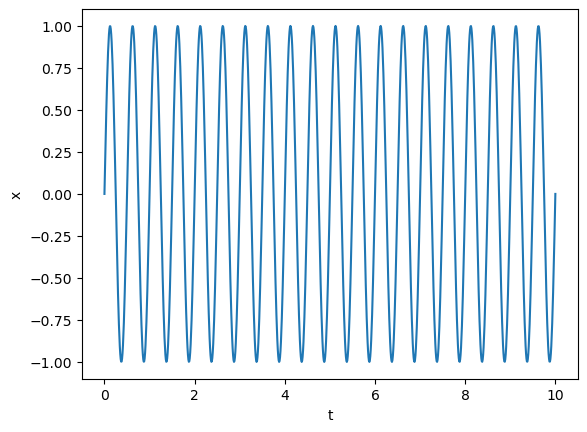

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

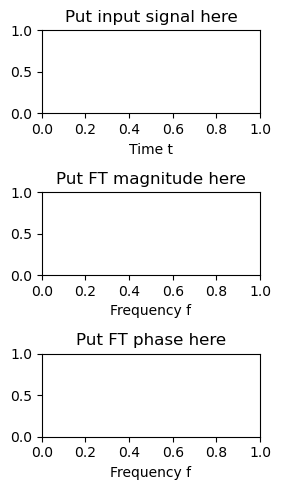

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitudenitudenitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

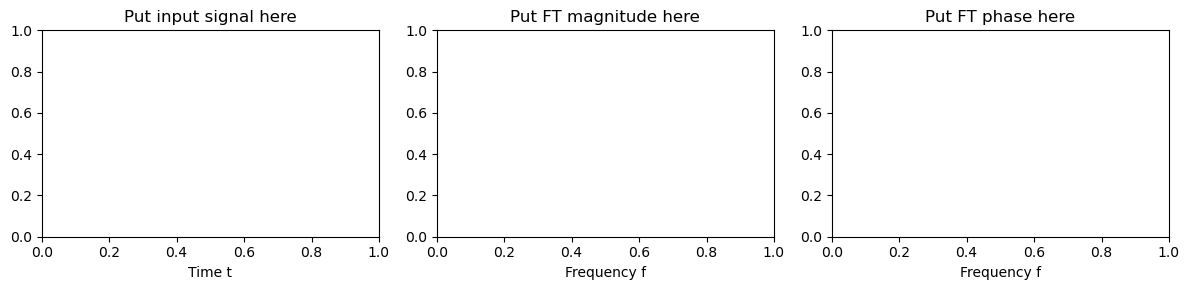

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitudenitudenitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

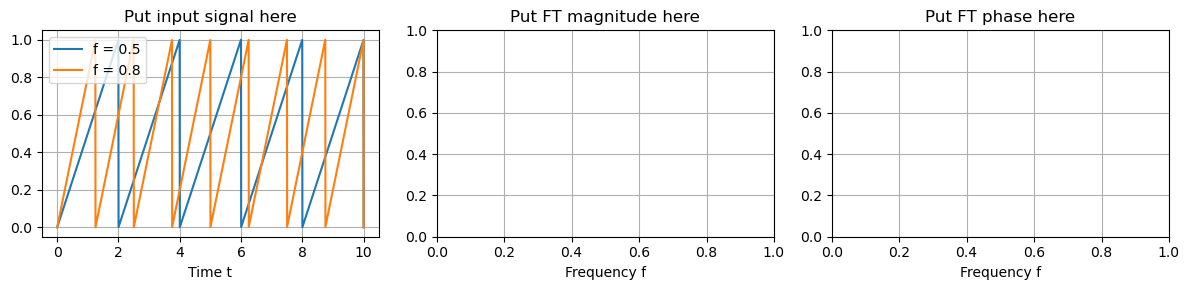

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitudenitudenitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



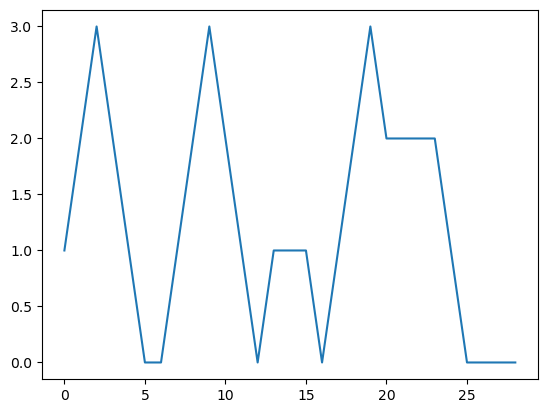

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

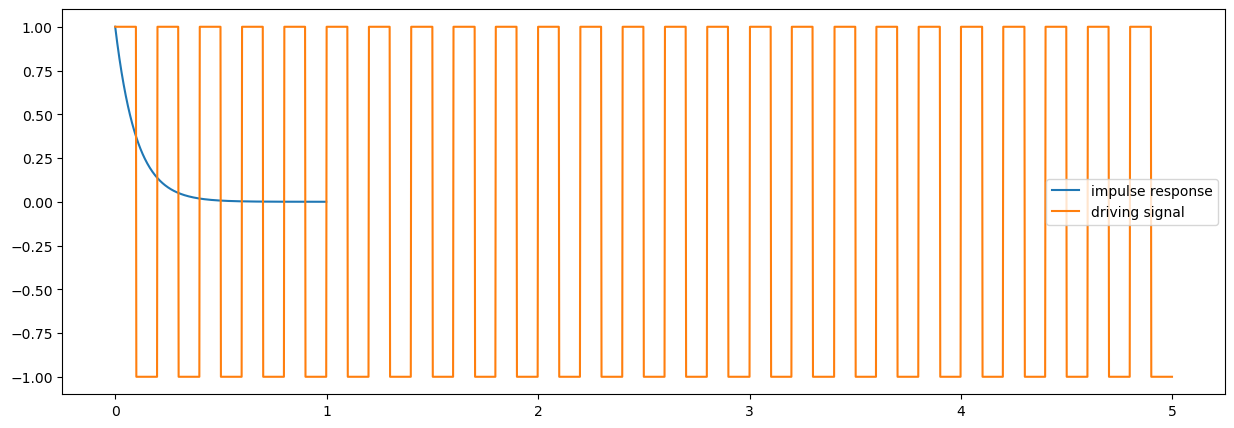

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

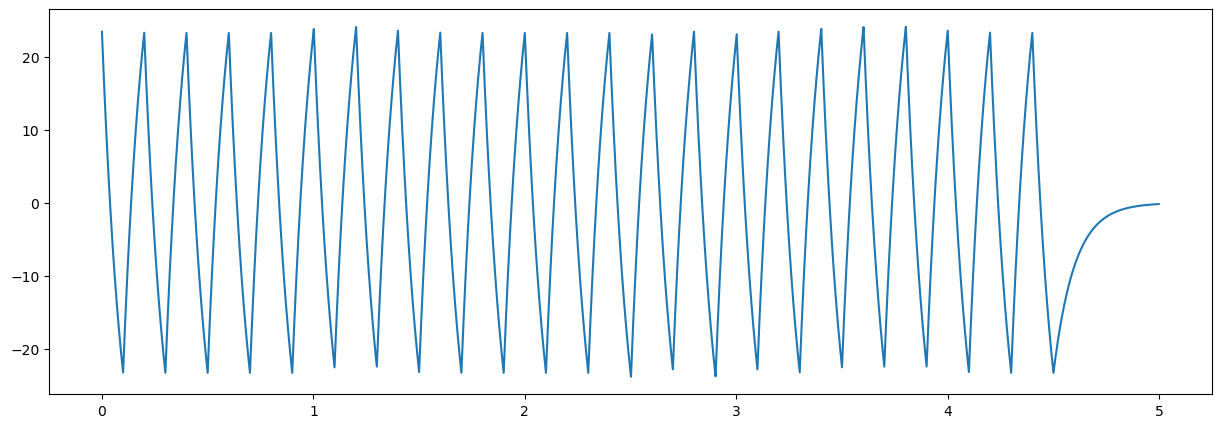

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

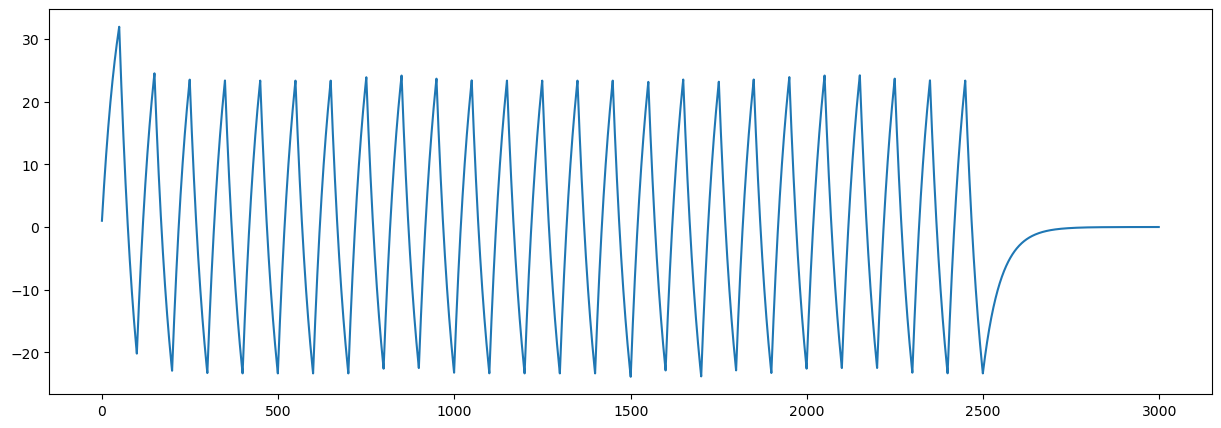

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)